# Light-Sheet smFRET Camera Simulation — Focusing-Depth Scan, 63x/NA 1.46 oil (DESIGN oil)

*Note: Partially vibe-coded with Mistral GLM-3*

*This notebook lives in and writes all outputs to `ATTO550_DNA_D80um2s_Alvium1800U158_NA1.46_oil_63x_depthscan/`*

Companion to `LightSheet_ATTO550_NA1.46_63x_oil_depthscan.ipynb`: the same
focusing-depth scan of the detection PSF, but with the **DESIGN immersion oil**
(ni = ni0 = 1.518, index-matched to the objective) instead of the mismatched
high-index oil (ni = 1.58).

**Why this companion:** with the design oil there is no over-correction — the
water-layer spherical aberration acts alone, so the PSF **degrades
monotonically with depth** (no recovery at 25 um). Comparing the two
notebooks isolates the effect of the immersion-oil choice:

| Depth | Mismatched oil (ni = 1.58) | Design oil (ni = 1.518) |
|---|---|---|
| 1 µm | poor (over-correction) | good (little water path) |
| 10 µm | improving | degraded |
| **25 µm** | **optimal (compensated)** | **degraded (~6x worse than at the coverslip)** |
| 50 µm | degraded again | severely degraded |

Together the two scans tell you: shallow imaging -> use the design oil;
imaging at 25 um -> the mismatched oil recovers the PSF ~4x; the design oil
*never* benefits from depth.

**Scan:** detection PSF at sheet depths **pz = 1, 5, 10, 25, 40, 50 µm**
above the coverslip, all results in combined figures with the focusing depth
indicated (identical figures/structure as the mismatched-oil notebook):
1. In-focus lateral PSF profiles at each depth
2. PSF peak and lateral FWHM vs. depth (monotonic deterioration curves)
3. Axial PSF profiles at each depth
4. XZ cross-sections at each depth

**Shared configuration:** ATTO550-DNA in aqueous buffer (ns = 1.333), Zeiss
63x/NA 1.46 oil detection, Mitutoyo sheet lens (NA 0.08), Alvium 1800 U-158
with 2x2 binning. Sections 2-4 retain the standard 25-um camera simulation
with the DESIGN oil, so the scan flows into rendered frames.

In [13]:
%matplotlib inline
import os
import sys
import numpy as np
import tables
import matplotlib.pyplot as plt
from matplotlib.colors import PowerNorm
import imageio.v3 as iio
import pybromo as pbm
import psfmodels

# LightSheetPSF lives in the repository base directory (one level up)
sys.path.insert(0, os.path.abspath('..'))
from lightsheet_psf import LightSheetPSF

# All results of this configuration are written into THIS notebook's directory
OUTPUT_DIR = os.path.abspath('.')          # .../ATTO550_DNA_D80um2s_Alvium1800U158_NA1.46_oil_63x
os.chdir(OUTPUT_DIR)
print('Output directory:', OUTPUT_DIR)

print('Numpy version:', np.__version__)
print('PyTables version:', tables.__version__)
print('PyBroMo version:', pbm.__version__)
print('psfmodels version:', psfmodels.__version__)

Output directory: /Users/tomkache/Documents/Arbeit/EAH/Software/python/Lightsheet_smFRET_Simulations/H2MM-FRET-Blinking/ATTO550_DNA_D80um2s_Alvium1800U158_NA1.46_oil_63x_depthscan
Numpy version: 1.26.4
PyTables version: 3.9.2
PyBroMo version: 0.8.1
psfmodels version: 0.3.3


## 1. Depth-dependent detection PSF: the scan

The detection PSF of the oil objective depends on the sheet depth `pz` through
the Gibson–Lanni model: the deeper the sheet, the more water the rays traverse.
With the DESIGN oil (ni = ni0 = 1.518) there is no compensation term — the
water-layer aberration accumulates monotonically, so the PSF degrades with
depth without any recovery. We compute the detection PSF stack at six depths
and compare them; the figure files are prefixed `designoil_` to distinguish
them from the mismatched-oil scan in the companion notebook.

*Note on the scan grid:* the lateral grid (`dxy = 0.0548 um`, `nx = 91`) is
finer than the rendering grid on purpose — it measures the true PSF FWHM
(~0.2 um, ~4 grid steps) without pixel-size bias.

In [14]:
# --- Depth scan of the detection PSF (DESIGN oil, water sample) ---
# Detection PSF at sheet depths pz = 1, 5, 10, 25, 40, 50 um.
# For each depth we compute the in-focus plane (z = pz) with psfmodels
# Gibson-Lanni, plus an axial profile, using the SAME optical parameters
# as the rendering PSF in section 3 (design oil ni = 1.518).
import psfmodels as psfm

depths_um = [1.0, 5.0, 10.0, 25.0, 40.0, 50.0, 75, 100, 150]

# optical parameters (identical to section 3)
det_NA, em_wvl = 1.46, 0.58
ns, ni, ni0 = 1.333, 1.518, 1.518     # water sample, DESIGN oil (index-matched)
ng, ng0, tg, tg0 = 1.515, 1.515, 170.0, 170.0

dxy_scan = 0.0548                     # fine lateral grid (1x sensor pixel)
nx_scan = 91                          # +-2.47 um support: plenty for the FWHM
dz_scan = 0.25                        # axial step for the profiles
nz_scan = 49                          # axial extent +-6 um

def in_focus_psf_at_depth(pz):
    """In-focus lateral PSF plane at depth pz (um) via Gibson-Lanni."""
    zv = pz + (np.arange(nz_scan) - nz_scan//2) * dz_scan   # absolute depths
    p = psfm.make_psf(zv, nx_scan, dxy=dxy_scan, dz=dz_scan, pz=pz,
                      NA=det_NA, wvl=em_wvl,
                      ns=ns, ni=ni, ni0=ni0, ng=ng, ng0=ng0,
                      tg=tg, tg0=tg0, ti0=150.0,
                      normalize=True, model='vectorial')
    iz = np.argmin(np.abs(zv - pz))    # the in-focus plane
    return zv, p, iz

psf_planes, axial_profiles, zvs = {}, {}, {}
for pz in depths_um:
    zv, p, iz = in_focus_psf_at_depth(pz)
    psf_planes[pz] = p[iz]
    axial_profiles[pz] = p[:, nx_scan//2, nx_scan//2]
    zvs[pz] = zv
    # metrics: sum-normalized peak + lateral FWHM of the central row
    k = p[iz]; kn = k / k.sum()
    row = kn[nx_scan//2]
    idx = np.where(row >= row.max()/2)[0]
    fwhm = (idx[-1] - idx[0] + 1) * dxy_scan
    print(f'pz = {pz:5.1f} um: peak {kn[nx_scan//2, nx_scan//2]*1e3:6.1f}e-3, '
          f'lateral FWHM {fwhm:.3f} um')

/var/folders/bb/1lj580x16_s1qch6b18q5j0c0000gn/T/ipykernel_41127/246754639.py:23: UserWarning: dz is ignored when providing a sequence for `z`.
  p = psfm.make_psf(zv, nx_scan, dxy=dxy_scan, dz=dz_scan, pz=pz,


pz =   1.0 um: peak   20.9e-3, lateral FWHM 0.274 um
pz =   5.0 um: peak   10.5e-3, lateral FWHM 0.384 um
pz =  10.0 um: peak    7.5e-3, lateral FWHM 0.384 um
pz =  25.0 um: peak    5.0e-3, lateral FWHM 0.493 um
pz =  40.0 um: peak    3.8e-3, lateral FWHM 0.603 um
pz =  50.0 um: peak    3.7e-3, lateral FWHM 0.603 um
pz =  75.0 um: peak    3.0e-3, lateral FWHM 0.603 um
pz = 100.0 um: peak    2.8e-3, lateral FWHM 0.603 um
pz = 150.0 um: peak    2.3e-3, lateral FWHM 0.712 um


### Figure 1: in-focus lateral PSF profiles vs. focusing depth

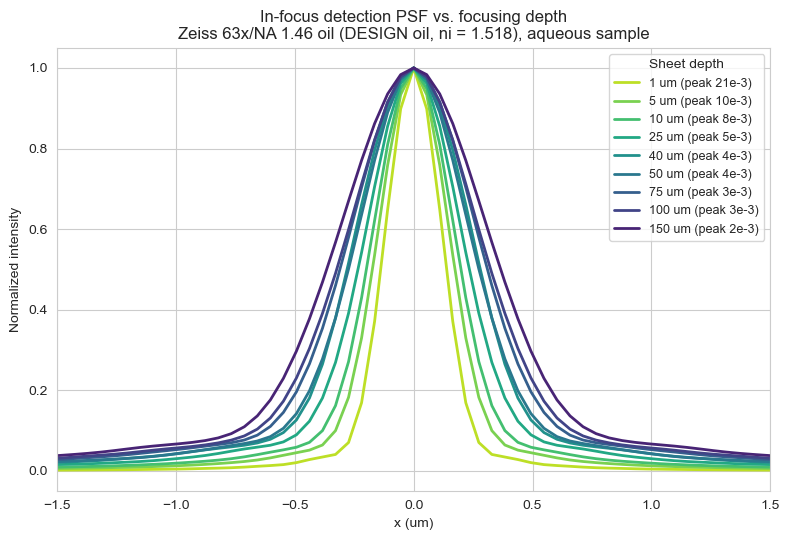

In [15]:
# --- Combined plot: in-focus lateral profiles, depth color-coded ---
fig, ax = plt.subplots(figsize=(8, 5.5))
colors = plt.cm.viridis(np.linspace(0.9, 0.1, len(depths_um)))
x_um = (np.arange(nx_scan) - nx_scan//2) * dxy_scan
for c, pz in zip(colors, depths_um):
    k = psf_planes[pz]; kn = k / k.sum()
    row = kn[nx_scan//2]
    ax.plot(x_um, row / row.max(), color=c, lw=2,
            label=f'{pz:.0f} um (peak {kn[nx_scan//2, nx_scan//2]*1e3:.0f}e-3)')
ax.set_xlim(-1.5, 1.5)
ax.set_xlabel('x (um)')
ax.set_ylabel('Normalized intensity')
ax.set_title('In-focus detection PSF vs. focusing depth\n'
             'Zeiss 63x/NA 1.46 oil (DESIGN oil, ni = 1.518), aqueous sample')
ax.legend(title='Sheet depth', fontsize=9)
plt.tight_layout()
#plt.savefig(os.path.join(OUTPUT_DIR, 'designoil_fig1_lateral_profiles.png'),
#            dpi=150, bbox_inches='tight');

### Figure 2: PSF peak and lateral FWHM vs. focusing depth

The peak (Strehl-like: sum-normalized in-focus peak — higher = tighter PSF)
decreases monotonically with depth (no compensation with the design oil); the
FWHM broadens correspondingly. The vertical line marks 25 um, where the
mismatched-oil companion notebook shows its optimum — the contrast between
the two scans is the argument for the oil choice.

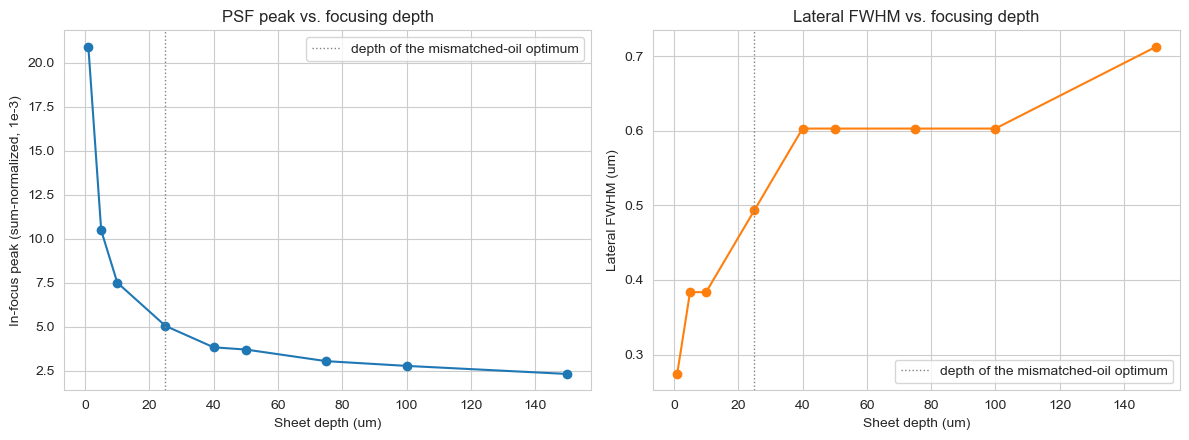

In [16]:
# --- Deterioration/recovery curves vs. depth ---
peaks, fwhms = [], []
for pz in depths_um:
    k = psf_planes[pz]; kn = k / k.sum()
    peaks.append(kn[nx_scan//2, nx_scan//2])
    row = kn[nx_scan//2]
    idx = np.where(row >= row.max()/2)[0]
    fwhms.append((idx[-1] - idx[0] + 1) * dxy_scan)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.5))
a1.plot(depths_um, np.array(peaks)*1e3, 'o-', color='C0')
a1.set_xlabel('Sheet depth (um)'); a1.set_ylabel('In-focus peak (sum-normalized, 1e-3)')
a1.set_title('PSF peak vs. focusing depth')
a1.axvline(25, color='gray', ls=':', lw=1, label='depth of the mismatched-oil optimum')
a1.legend()

a2.plot(depths_um, fwhms, 'o-', color='C1')
a2.set_xlabel('Sheet depth (um)'); a2.set_ylabel('Lateral FWHM (um)')
a2.set_title('Lateral FWHM vs. focusing depth')
a2.axvline(25, color='gray', ls=':', lw=1, label='depth of the mismatched-oil optimum')
a2.legend()
plt.tight_layout()
#plt.savefig(os.path.join(OUTPUT_DIR, 'designoil_fig2_peak_fwhm_vs_depth.png'),
#            dpi=150, bbox_inches='tight');

### Figure 3: axial PSF profiles vs. focusing depth

The axial response around each sheet position (relative defocus from the
sheet plane). The mismatched-oil compensation produces an asymmetric axial
PSF away from the tuned depth.

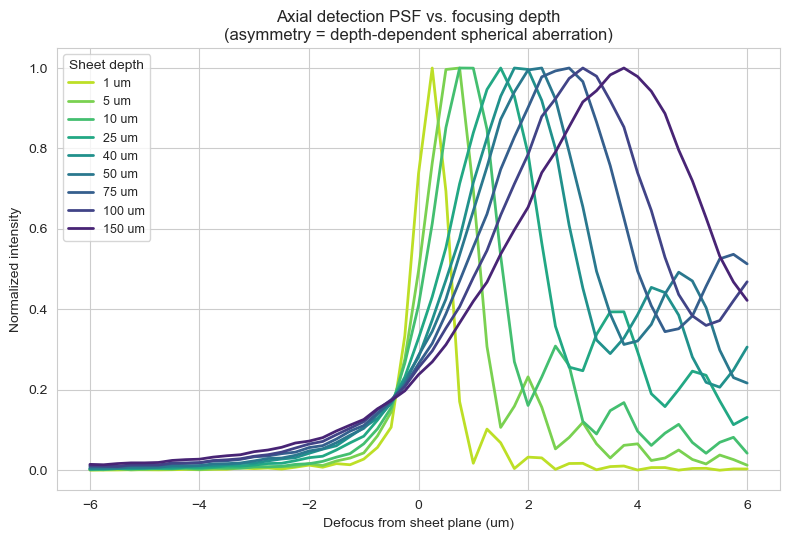

In [17]:
# --- Combined plot: axial profiles (relative defocus), depth color-coded ---
fig, ax = plt.subplots(figsize=(8, 5.5))
for c, pz in zip(colors, depths_um):
    prof = axial_profiles[pz] / axial_profiles[pz].max()
    z_rel = zvs[pz] - pz          # defocus relative to the sheet plane
    ax.plot(z_rel, prof, color=c, lw=2, label=f'{pz:.0f} um')
ax.set_xlabel('Defocus from sheet plane (um)')
ax.set_ylabel('Normalized intensity')
ax.set_title('Axial detection PSF vs. focusing depth\n'
             '(asymmetry = depth-dependent spherical aberration)')
ax.legend(title='Sheet depth', fontsize=9)
plt.tight_layout()
#plt.savefig(os.path.join(OUTPUT_DIR, 'designoil_fig3_axial_profiles.png'),
#            dpi=150, bbox_inches='tight');

### Figure 4: XZ cross-sections of the detection PSF at each depth

One XZ panel per depth (slice at y = 0 through the sheet plane), arranged as
a combined grid with the focusing depth in each panel title.

/var/folders/bb/1lj580x16_s1qch6b18q5j0c0000gn/T/ipykernel_41127/246754639.py:23: UserWarning: dz is ignored when providing a sequence for `z`.
  p = psfm.make_psf(zv, nx_scan, dxy=dxy_scan, dz=dz_scan, pz=pz,


Text(0.5, 0.98, 'Detection PSF XZ cross-sections vs. focusing depth\nZeiss 63x/NA 1.46 oil (DESIGN oil, ni = 1.518), aqueous sample')

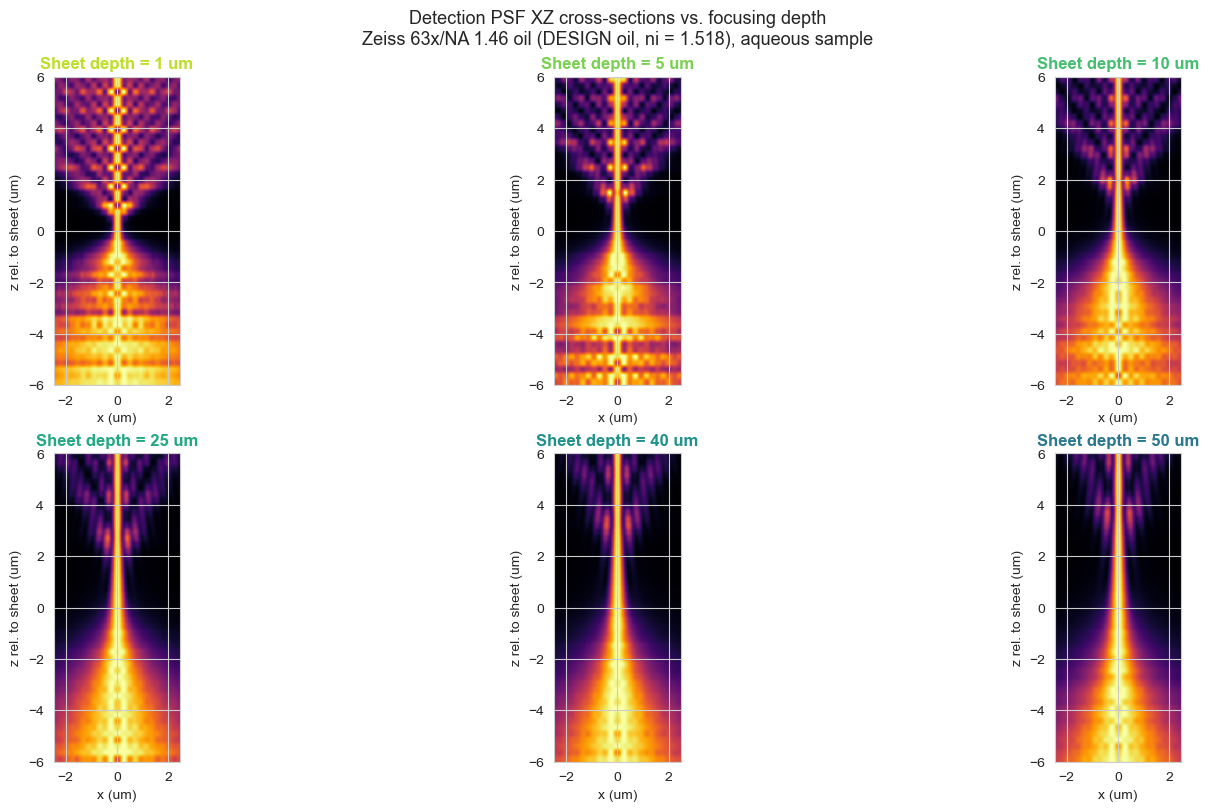

In [18]:
# --- Combined grid: XZ cross-sections at each depth ---
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
extent = [-(nx_scan//2)*dxy_scan, (nx_scan//2)*dxy_scan, -6, 6]
for ax_i, (pz, c) in zip(axes.ravel(), zip(depths_um, colors)):
    zv, p, iz = in_focus_psf_at_depth(pz)
    xz = p[:, nx_scan//2, :]                      # (nz, nx) slice at y = 0
    xz_norm = xz / xz.max(axis=1, keepdims=True)   # per-z-row normalize: show the cone shape
    im = ax_i.imshow(xz_norm, extent=extent, origin='lower', cmap='inferno',
                     aspect='equal', norm=PowerNorm(gamma=0.8))
    ax_i.set_title(f'Sheet depth = {pz:.0f} um', color=c, fontweight='bold')
    ax_i.set_xlabel('x (um)'); ax_i.set_ylabel('z rel. to sheet (um)')
fig.suptitle('Detection PSF XZ cross-sections vs. focusing depth\n'
             'Zeiss 63x/NA 1.46 oil (DESIGN oil, ni = 1.518), aqueous sample',
             fontsize=13)
#plt.savefig(os.path.join(OUTPUT_DIR, 'designoil_fig4_xz_sections.png'),
#            dpi=150, bbox_inches='tight');

/var/folders/bb/1lj580x16_s1qch6b18q5j0c0000gn/T/ipykernel_41127/246754639.py:23: UserWarning: dz is ignored when providing a sequence for `z`.
  p = psfm.make_psf(zv, nx_scan, dxy=dxy_scan, dz=dz_scan, pz=pz,


Text(0.5, 0.98, 'Effective light-sheet PSF (excitation x detection) XZ sections\nZeiss 63x/NA 1.46 oil (MISMATCHED, ni = 1.58), sheet NA 0.08, aqueous sample')

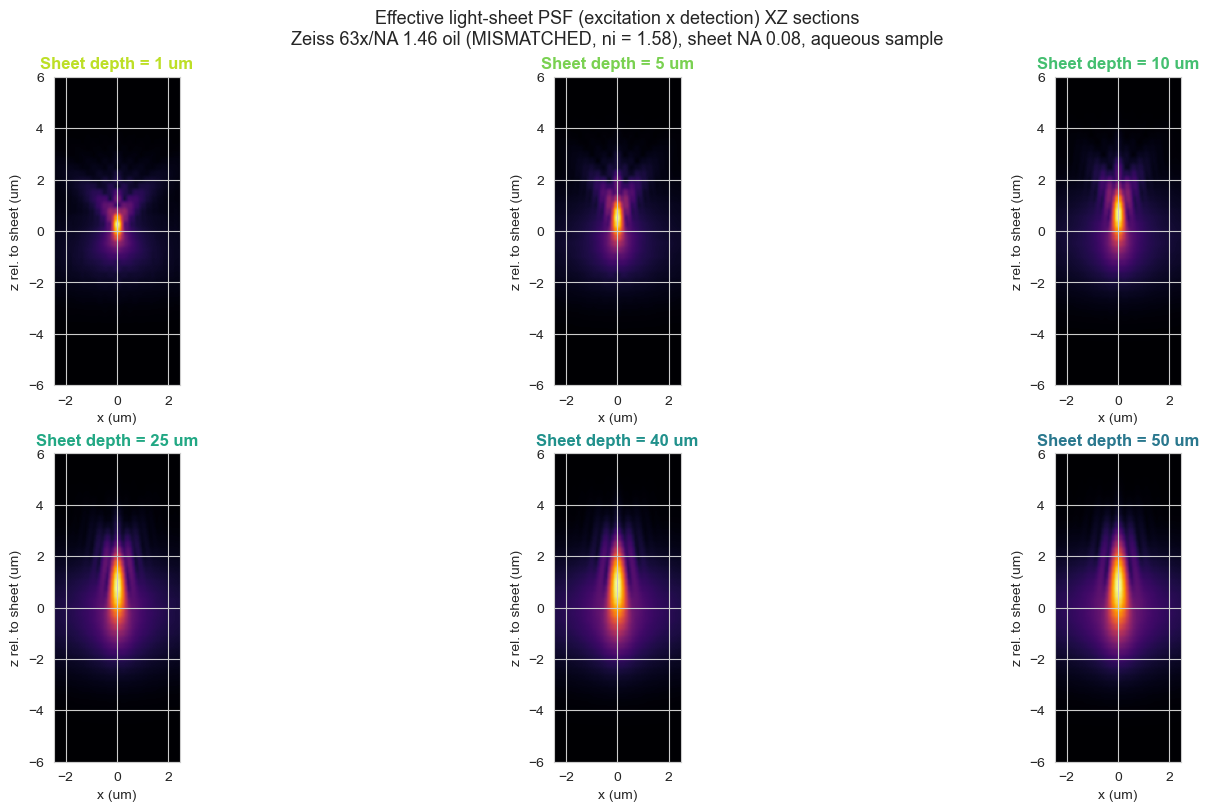

In [19]:
# --- Effective PSF (excitation sheet x detection) vs. focusing depth ---
# The effective PSF is what a molecule actually experiences: the detection
# PSF at its defocus, multiplied by the sheet excitation at its z position.
# Here: the effective XZ cross-section at each sheet depth, plus the axial
# profile of the effective PSF (the detection cone carved by the sheet).
# The sheet sits AT z=0 of each panel (defocus relative to the sheet plane).

sheet_waist = 0.532 / (np.pi * 0.08)      # w0 (um), same as the config notebooks
sheet_exc = np.exp(-2 * (np.arange(nz_scan) - nz_scan//2) * dz_scan / sheet_waist * 0)  # placeholder

# effective axial excitation profile over the scan z-grid (defocus rel. to sheet)
z_rel_scan = (np.arange(nz_scan) - nz_scan//2) * dz_scan
sheet_exc = np.exp(-2 * (z_rel_scan / sheet_waist) ** 2)          # (nz,)

fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
extent = [-(nx_scan//2)*dxy_scan, (nx_scan//2)*dxy_scan,
          z_rel_scan[0], z_rel_scan[-1]]
for ax_i, (pz, c) in zip(axes.ravel(), zip(depths_um, colors)):
    zv, p, iz = in_focus_psf_at_depth(pz)
    # effective PSF: detection stack x sheet profile (broadcast over x, y)
    eff = p * sheet_exc[:, None, None]
    xz = eff[:, nx_scan//2, :]
    xz_norm = xz / xz.max()                        # ONE scale per depth: the
                                                   # in-focus plane is the brightest
    im = ax_i.imshow(xz_norm, extent=extent, origin='lower', cmap='inferno',
                     aspect='equal', norm=PowerNorm(gamma=0.4))
    ax_i.set_title(f'Sheet depth = {pz:.0f} um', color=c, fontweight='bold')
    ax_i.set_xlabel('x (um)'); ax_i.set_ylabel('z rel. to sheet (um)')
fig.suptitle('Effective light-sheet PSF (excitation x detection) XZ sections\n'
             'Zeiss 63x/NA 1.46 oil (MISMATCHED, ni = 1.58), sheet NA 0.08, '
             'aqueous sample', fontsize=13)
#plt.savefig(os.path.join(OUTPUT_DIR, 'depthscan_fig5_effective_xz.png'),
#            dpi=150, bbox_inches='tight');

/var/folders/bb/1lj580x16_s1qch6b18q5j0c0000gn/T/ipykernel_41127/246754639.py:23: UserWarning: dz is ignored when providing a sequence for `z`.
  p = psfm.make_psf(zv, nx_scan, dxy=dxy_scan, dz=dz_scan, pz=pz,


Text(0.5, 0.98, 'Effective light-sheet PSF (excitation x detection) XZ sections\nZeiss 63x/NA 1.46 oil (MISMATCHED, ni = 1.58), sheet NA 0.08, aqueous sample')

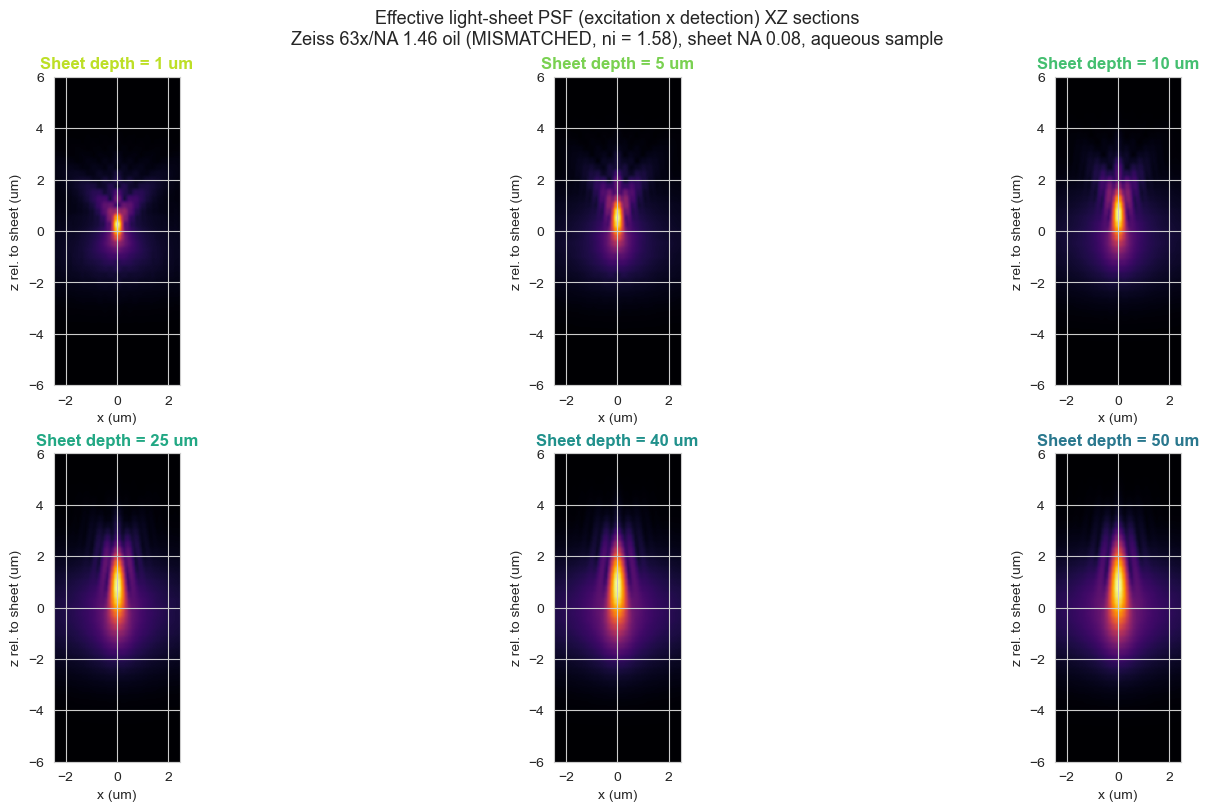

In [20]:
# --- Effective PSF (excitation sheet x detection) vs. focusing depth ---
# The effective PSF is what a molecule actually experiences: the detection
# PSF at its defocus, multiplied by the sheet excitation at its z position.
# Here: the effective XZ cross-section at each sheet depth, plus the axial
# profile of the effective PSF (the detection cone carved by the sheet).
# The sheet sits AT z=0 of each panel (defocus relative to the sheet plane).

sheet_waist = 0.532 / (np.pi * 0.08)      # w0 (um), same as the config notebooks
sheet_exc = np.exp(-2 * (np.arange(nz_scan) - nz_scan//2) * dz_scan / sheet_waist * 0)  # placeholder

# effective axial excitation profile over the scan z-grid (defocus rel. to sheet)
z_rel_scan = (np.arange(nz_scan) - nz_scan//2) * dz_scan
sheet_exc = np.exp(-2 * (z_rel_scan / sheet_waist) ** 2)          # (nz,)

fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
extent = [-(nx_scan//2)*dxy_scan, (nx_scan//2)*dxy_scan,
          z_rel_scan[0], z_rel_scan[-1]]
for ax_i, (pz, c) in zip(axes.ravel(), zip(depths_um, colors)):
    zv, p, iz = in_focus_psf_at_depth(pz)
    # effective PSF: detection stack x sheet profile (broadcast over x, y)
    eff = p * sheet_exc[:, None, None]
    xz = eff[:, nx_scan//2, :]
    xz_norm = xz / xz.max()                        # ONE scale per depth: the
                                                   # in-focus plane is the brightest
    im = ax_i.imshow(xz_norm, extent=extent, origin='lower', cmap='inferno',
                     aspect='equal', norm=PowerNorm(gamma=0.4))
    ax_i.set_title(f'Sheet depth = {pz:.0f} um', color=c, fontweight='bold')
    ax_i.set_xlabel('x (um)'); ax_i.set_ylabel('z rel. to sheet (um)')
fig.suptitle('Effective light-sheet PSF (excitation x detection) XZ sections\n'
             'Zeiss 63x/NA 1.46 oil (MISMATCHED, ni = 1.58), sheet NA 0.08, '
             'aqueous sample', fontsize=13)
#plt.savefig(os.path.join(OUTPUT_DIR, 'depthscan_fig5_effective_xz.png'),
#            dpi=150, bbox_inches='tight')